# 📰 Pipeline de sentimiento · XLM-RLnews-8
Análisis de **78,360 noticias** (de, en, es, fr, pt) con `nuovoel/xlm-rlnews-8`.

**Orden de uso:** ejecuta las secciones de arriba hacia abajo. Las secciones 1–4 se hacen una vez por sesión;
la 5 es la muestra de prueba; la 7 es la corrida completa.

> ⚠️ Menú **Entorno de ejecución → Cambiar tipo de entorno** y elige una **GPU** antes de empezar.

## 1 · Configuración

In [1]:
# ====== PARÁMETROS (lo único que normalmente tocas) ======
PRECISION   = "fp16"   # "fp32" (referencia, lento) | "fp16" (T4) | "bf16" (A100/L4)
LOTE        = 16       # baja a 8 o 4 si aparece "out of memory"
MAX_FRAG    = 0        # 0 = sin tope; p. ej. 30 limita noticias gigantes (muestreo uniforme)
MUESTRA     = 100      # noticias por idioma en la prueba
ETIQUETAS   = ""       # SOLO si los autores confirman el orden, p. ej. "negative neutral positive"
# ==========================================================

BASE   = "/content/drive/MyDrive/pipeline_sentimientos"
CACHE  = "/content/cache_modelos"      # disco local: evita corrupción de descargas en Drive
SCRIPT = f"{BASE}/ejecutar_modelo.py"

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os, torch, transformers
os.chdir(BASE)
os.environ["HF_HUB_DISABLE_XET"] = "1"   # descarga simple y estable
print("torch:", torch.__version__, "| transformers:", transformers.__version__)
assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno"
print("GPU:", torch.cuda.get_device_name(0))
print("Script :", os.path.exists(SCRIPT))
print("Datos  :", os.path.exists(f"{BASE}/datos/preparados/noticias_preparadas.parquet"))

Mounted at /content/drive
torch: 2.14.1+cu130 | transformers: 5.22.1
GPU: Tesla T4
Script : True
Datos  : True


## 2 · Verificar el modelo (descarga + huella SHA-256)
Descarga `rln8.pt` al disco local y comprueba que coincide con Hugging Face. Tarda ~1 min la primera vez en cada sesión.

In [3]:
import hashlib
from huggingface_hub import HfApi, hf_hub_download

info = HfApi().model_info("nuovoel/xlm-rlnews-8", files_metadata=True)
esperado = {s.rfilename: s.lfs.sha256 for s in info.siblings if s.lfs}["rln8.pt"]
ruta = hf_hub_download("nuovoel/xlm-rlnews-8", "rln8.pt", cache_dir=CACHE)

h = hashlib.sha256()
with open(ruta, "rb") as f:
    for b in iter(lambda: f.read(1 << 20), b""):
        h.update(b)
print("Tamaño :", f"{os.path.getsize(ruta)/1e9:.2f} GB")
print("¿Archivo íntegro?", h.hexdigest() == esperado)

rln8.pt: reconstructing file:   0%|          |  0.00B / 2.24GB            

rln8.pt: downloading bytes:           |  0.00B            

Tamaño : 2.24 GB
¿Archivo íntegro? True


In [4]:
# Construye el comando base una sola vez
CMD_BASE = f"python ejecutar_modelo.py --dir-modelos {CACHE} --precision {PRECISION} --lote {LOTE}"
if MAX_FRAG:  CMD_BASE += f" --max-fragmentos {MAX_FRAG}"
if ETIQUETAS: CMD_BASE += f" --etiquetas {ETIQUETAS}"
print(CMD_BASE)

python ejecutar_modelo.py --dir-modelos /content/cache_modelos --precision fp16 --lote 16


## 3 · Contar fragmentos (sin cargar el modelo)
Sirve para ver el tamaño real del trabajo y detectar noticias anómalas (p. ej. la alemana con 287 fragmentos).

In [5]:
!{CMD_BASE} --solo-contar

Entrada : /content/drive/MyDrive/pipeline_sentimientos/datos/preparados/noticias_preparadas.parquet
Salida  : /content/drive/MyDrive/pipeline_sentimientos/resultados
Noticias a procesar: 78,360 de 78,360 en el archivo preparado
Cargando tokenizer ...
   tokenizer: xlm-roberta-large
   (no está en la caché local: descargando desde Hugging Face; solo ocurre la primera vez)
config.json: 100% 616/616 [00:00<00:00, 2.91MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 130kB/s]
sentencepiece.bpe.model: 100% 5.07M/5.07M [00:00<00:00, 47.0MB/s]
tokenizer.json: 100% 9.10M/9.10M [00:00<00:00, 28.0MB/s]
contando: 100% 78360/78360 [05:41<00:00, 229.79noticia/s]

Fragmentos totales (max 512 tokens c/u): 210,120 | tokens: 82,925,443
        noticias  fragmentos  fr_por_noticia  max_fr
idioma                                              
de          9592       25126            2.62     287
en         20136       62437            3.10      96
es         13053       34845            2.67      4

## 4 · Prueba rápida con muestra
Procesa `MUESTRA` noticias por idioma y guarda en `resultados/prueba/`. Mira la velocidad (fragmentos/s) y la estimación final.

In [6]:
!{CMD_BASE} --muestra {MUESTRA} --forzar

Entrada : /content/drive/MyDrive/pipeline_sentimientos/datos/preparados/noticias_preparadas.parquet
Salida  : /content/drive/MyDrive/pipeline_sentimientos/resultados/prueba
*** MODO MUESTRA: 100 noticias por idioma (500 en total) ***
Noticias a procesar: 500 de 78,360 en el archivo preparado
Cargando tokenizer ...
   tokenizer: xlm-roberta-large
Cargando pesos 'rln8.pt' de 'nuovoel/xlm-rlnews-8' en CUDA (torch 2.14.1+cu130, hilos CPU: 1) ...
Modelo OK | etiquetas del modelo: ['LABEL_0', 'LABEL_1', 'LABEL_2']
AVISO: las etiquetas NO son exactamente positivo/negativo/neutral; se conservan tal cual (sin traducir). Consulta el model card antes de interpretarlas.
Con resultados válidos reutilizados: 0 | por calcular: 500
sentimientos: 100% 500/500 [00:27<00:00, 18.29noticia/s, frag_s=56.5]

Listo en 76 s. Noticias ok: 500 | con error: 0
Fragmentos calculados ahora: 1,386 a 58.2 fragmentos/s
Archivos en /content/drive/MyDrive/pipeline_sentimientos/resultados/prueba:
  sentimientos_por_notici

## 5 · Revisar los resultados de la muestra

In [7]:
import pandas as pd, matplotlib.pyplot as plt
DIR = f"{BASE}/resultados/prueba"      # cambia a f"{BASE}/resultados" para ver la corrida completa

df = pd.read_parquet(f"{DIR}/sentimientos_por_noticia.parquet")
print("Noticias:", len(df), "| estados:", df["estado"].value_counts().to_dict())
ok = df[df["estado"] == "ok"].copy()
display(pd.read_csv(f"{DIR}/resumen_por_idioma.csv"))
ok.head()

Noticias: 500 | estados: {'ok': 500}


,idioma,categoria,noticias,pct_noticias
0,de,LABEL_1,96,96.0
1,de,LABEL_0,2,2.0
2,de,LABEL_2,2,2.0
3,en,LABEL_2,39,39.0
4,en,LABEL_1,37,37.0
5,en,LABEL_0,24,24.0
6,es,LABEL_1,56,56.0
7,es,LABEL_2,25,25.0
8,es,LABEL_0,19,19.0
9,fr,LABEL_2,53,53.0


,id,idioma,diario,tipo,rol,fecha_final,anio_pub,mes_pub,anio_mes,trimestre,...,media_LABEL_0,media_LABEL_1,media_LABEL_2,max_LABEL_0,max_LABEL_1,max_LABEL_2,prev_LABEL_0,prev_LABEL_1,prev_LABEL_2,error
0,18a548a6bd89,de,heise.de,tecnologia,principal,2021-01-28,2021,1,2021-01,2021Q1,...,0.026744,0.662669,0.310587,0.026744,0.662669,0.310587,0.0,1.0,0.0,NaN
1,a637ad46c0f2,de,heise.de,tecnologia,principal,2021-04-16,2021,4,2021-04,2021Q2,...,0.222007,0.703854,0.074138,0.263490,0.739070,0.089878,0.0,1.0,0.0,NaN
2,ce5cbb1a26ad,de,faz.net,generalista,principal,2023-01-27,2023,1,2023-01,2023Q1,...,0.045747,0.758785,0.195468,0.045747,0.758785,0.195468,0.0,1.0,0.0,NaN
3,e3e90414984f,de,focus.de,generalista,principal,2023-02-03,2023,2,2023-02,2023Q1,...,0.078647,0.820319,0.101034,0.078647,0.820319,0.101034,0.0,1.0,0.0,NaN
4,00e4e87c932a,de,heise.de,tecnologia,principal,2023-03-15,2023,3,2023-03,2023Q1,...,0.088558,0.855933,0.055509,0.187012,0.909419,0.144002,0.0,1.0,0.0,NaN


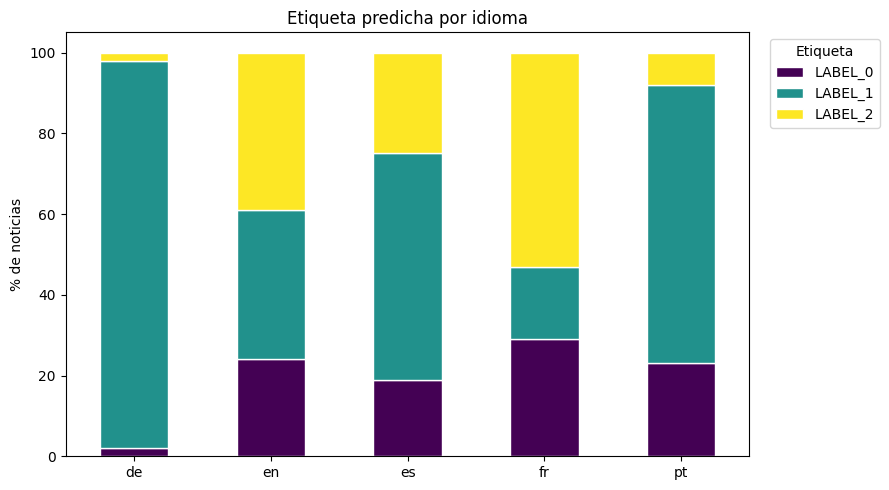

etiqueta_predicha,LABEL_0,LABEL_1,LABEL_2
idioma,,,
de,2.0,96.0,2.0
en,24.0,37.0,39.0
es,19.0,56.0,25.0
fr,29.0,18.0,53.0
pt,23.0,69.0,8.0


In [8]:
# Distribución de etiquetas por idioma (% de noticias)
tabla = ok.groupby(["idioma", "etiqueta_predicha"]).size().unstack(fill_value=0)
pct = tabla.div(tabla.sum(axis=1), axis=0) * 100

ax = pct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="viridis", edgecolor="white")
ax.set_ylabel("% de noticias"); ax.set_xlabel("")
ax.set_title("Etiqueta predicha por idioma")
plt.xticks(rotation=0); plt.legend(title="Etiqueta", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(pct.round(1))

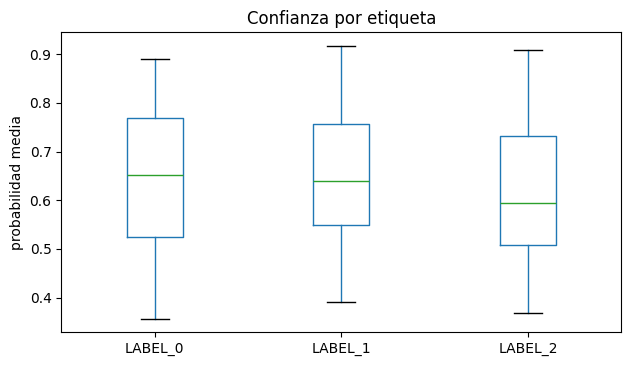

In [9]:
# ¿Qué tan seguro está el modelo? Probabilidad media de la etiqueta ganadora
cols = [c for c in ok.columns if c.startswith("media_")]
ok["confianza"] = ok[cols].max(axis=1)
ok.boxplot(column="confianza", by="etiqueta_predicha", figsize=(7, 4), grid=False)
plt.suptitle(""); plt.title("Confianza por etiqueta"); plt.xlabel(""); plt.ylabel("probabilidad media")
plt.show()

In [10]:
# Ejemplos reales por etiqueta (los más seguros) para interpretar qué significa cada LABEL
txt = pd.read_parquet(f"{BASE}/datos/preparados/noticias_preparadas.parquet", columns=["id", "texto_limpio"])
ej = ok.merge(txt, on="id")
for et, g in ej.groupby("etiqueta_predicha"):
    print(f"\n=== {et} ===")
    for _, r in g.nlargest(3, "confianza").iterrows():
        print(f"[{r['idioma']}] conf={r['confianza']:.2f} | {r['texto_limpio'][:250].replace(chr(10), ' ')}…")


=== LABEL_0 ===
[fr] conf=0.89 | Les chercheurs du Tow Center for Digital Journalism ont évalué huit moteurs de recherche IA et constaté des erreurs fréquentes, des citations trompeuses et des liens falsifiés. Ces outils peinent à fournir des informations fiables et à identifier cor…
[pt] conf=0.89 | O ChatGPT, chatbot da startup americana OpenAI, assombra profissionais de diversas áreas e ameaça seus empregos. Advogados, médicos, roteiristas e colunistas de jornais estão apreensivos. A qualquer momento a inteligência artificial pode reproduzir s…
[fr] conf=0.88 | Le géant à l'origine de ChatGPT en a marre des actions intentées par Elon Musk contre lui. Et à son tour, OpenAI vient faire valoir ses droits devant la justice, pour faire cesser ce qu'elle voit comme un « harcèlement ». On le sait depuis le temps. …

=== LABEL_1 ===
[de] conf=0.92 | Databricks will es offenbar wissen: Nachdem das Unternehmen 2023 als Reaktion auf ChatGPT bereits das große Sprachmodell Dolly veröffentlicht 

> 🔎 **Antes de seguir:** el modelo solo expone `LABEL_0/1/2`. Usa los ejemplos de arriba y el *model card*
> de `nuovoel/xlm-rlnews-8` para saber qué significa cada una. Si los autores confirman el orden, rellena `ETIQUETAS` en la sección 1.

## 6 · Corrida completa (78,360 noticias)
Guarda progreso por bloques. Si Colab se desconecta, **vuelve a ejecutar esta misma celda** (secciones 1 y 2 antes) y retoma donde quedó.

In [11]:
!{CMD_BASE}

Entrada : /content/drive/MyDrive/pipeline_sentimientos/datos/preparados/noticias_preparadas.parquet
Salida  : /content/drive/MyDrive/pipeline_sentimientos/resultados
Noticias a procesar: 78,360 de 78,360 en el archivo preparado
Cargando tokenizer ...
   tokenizer: xlm-roberta-large
Cargando pesos 'rln8.pt' de 'nuovoel/xlm-rlnews-8' en CUDA (torch 2.14.1+cu130, hilos CPU: 1) ...
Modelo OK | etiquetas del modelo: ['LABEL_0', 'LABEL_1', 'LABEL_2']
AVISO: las etiquetas NO son exactamente positivo/negativo/neutral; se conservan tal cual (sin traducir). Consulta el model card antes de interpretarlas.
Con resultados válidos reutilizados: 500 | por calcular: 77,860
sentimientos: 100% 77860/77860 [1:15:05<00:00, 17.28noticia/s, frag_s=50.7]

Listo en 4549 s. Noticias ok: 78,360 | con error: 0
Fragmentos calculados ahora: 208,734 a 50.7 fragmentos/s
Archivos en /content/drive/MyDrive/pipeline_sentimientos/resultados:
  sentimientos_por_noticia.parquet | sentimientos_por_fragmento.parquet | resum

## 7 · Resultados finales
Vuelve a ejecutar la sección 5 cambiando `DIR` a `f"{BASE}/resultados"`, o usa esta celda para descargar a tu equipo.

In [12]:
from google.colab import files
files.download(f"{BASE}/resultados/resumen_por_idioma.csv")
# Los parquet grandes ya quedan en tu Drive: resultados/sentimientos_por_noticia.parquet

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>